##  Online Food Delivery: Customer Behaviour Analysis

### Introduction
Online food delivery has become part of everyday life, especially for young people in cities. This project looks at a dataset of customers who use online food ordering and tries to understand **who they are** and **who is more likely to order**.

### Objective
To explore how a customer's background (age, gender, marital status, occupation, income, education, family size and location) is related to their online food ordering behaviour.

### Key Questions
- What kind of customers use online food delivery the most?
- Which groups are more likely to say **Yes** to ordering?

In [1]:
# import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [35]:
#Load the dataset
df = pd.read_csv('C:/Users/KINN/Desktop/PYTHON FOR DATA ANALYTICS AND DATA APPS/Online Food Delivery Analysis/Data/online food delivery dataset.csv')

In [10]:
# Preview the dataset
df.head()


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


In [4]:
df.shape

(388, 14)

The dataset contains 388 rows and 14 columns

In [5]:
# Check for missing values
df.isnull().sum()

Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualifications    0
Family size                   0
Customer Type                 0
latitude                      0
longitude                     0
Pin code                      0
Output                        0
Feedback                      0
Unnamed: 13                   0
dtype: int64

The dataset has no missing values

In [6]:
# Check for duplicates
df.duplicated().sum()

np.int64(103)

There are 103  duplicates

### Data Cleaning

In [15]:
# drop duplicates
df =df.drop_duplicates()

df.shape


(285, 14)

In [36]:
# 'Unnamed: 13' looks like a copy of 'Output'.:
(df['Unnamed: 13'] == df['Output']).all()


np.True_

In [ ]:
# It is the same, so we drop it
df = df.drop(columns='Unnamed: 13')

## Exploratory Data Analysis (EDA)

In [17]:
df.describe()

,Age,Family size,latitude,longitude,Pin code
count,285.000000,285.000000,285.000000,285.000000,285.000000
mean,24.677193,3.270175,12.973429,77.597593,560037.280702
std,3.040977,1.361178,0.043964,0.053557,30.738306
min,18.000000,1.000000,12.865200,77.484200,560001.000000
25%,23.000000,2.000000,12.943800,77.563500,560010.000000
50%,24.000000,3.000000,12.977000,77.587700,560028.000000
75%,26.000000,4.000000,12.998000,77.622700,560066.000000
max,33.000000,6.000000,13.102000,77.758200,560109.000000


Most of the  customers average 24 years and family size of 3. The oldest customer is 33 years old whereas the youngest is 18 years old. The biggest family size consists of 6 members. 

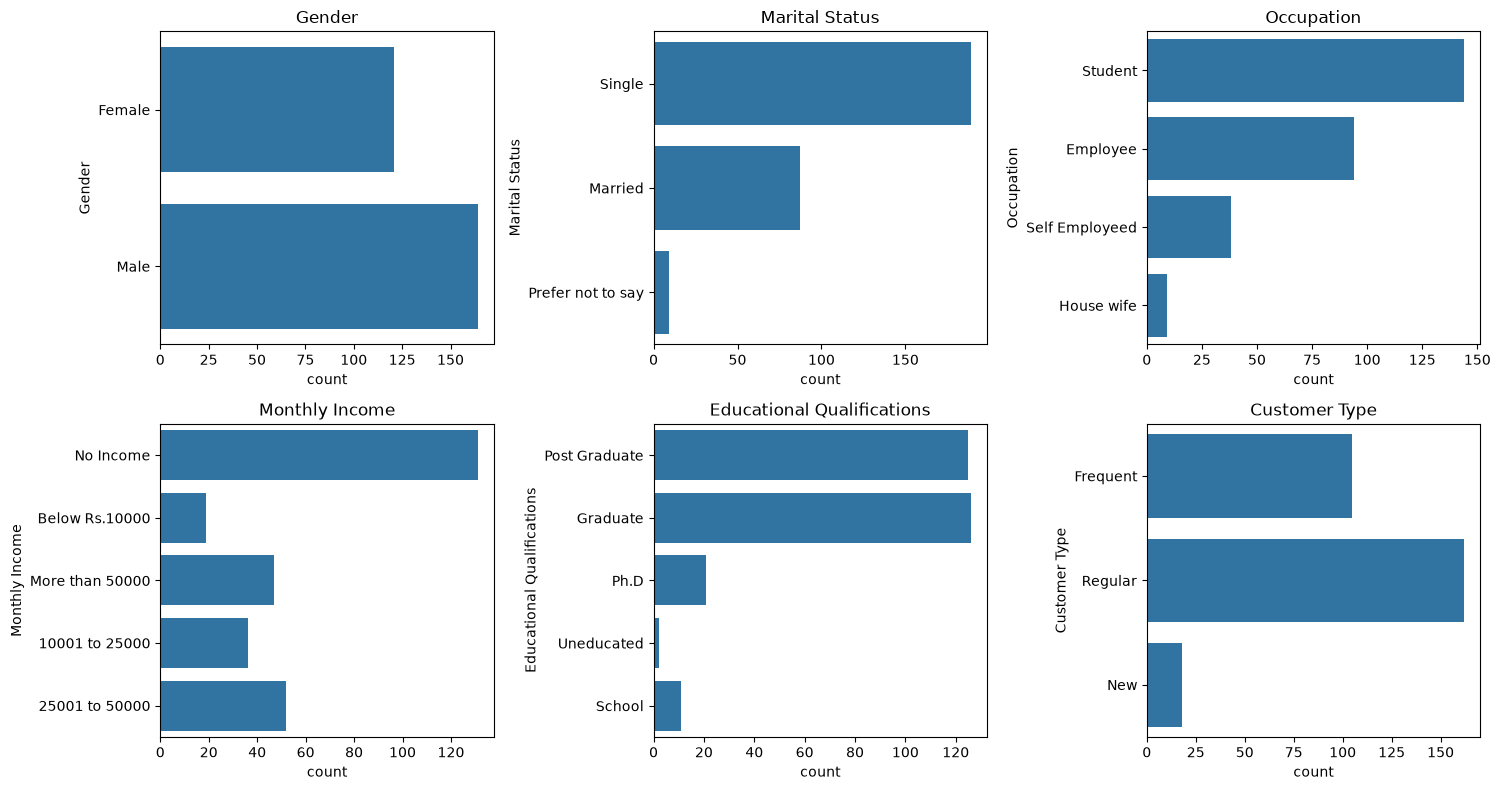

In [18]:
# Explore the number of customers in each group:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
columns = ['Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Customer Type']

for ax, col in zip(axes.flatten(), columns):
    sns.countplot(y=col, data=df, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.savefig('Customers in Each Group.png')
plt.show()

For the gender category, more male, approximately 150+ are ordering the food online. This can be attributed to the fact that more men answered the survey. Additionally, women are more likely to do their cooking at home, culturally. 

Single customers account for the highest online orders at 150+, than the rest who are married or prefer not to say their marital status. This might be because, most of the customers are young and likely to be single people, and have no reponsibilities of cooking for anyone other than for themselves and would therefore be comfortable eating out.

When it comes to occupation, half of the customers (about 50%) are students. Employees are about 33%, self-employed about 13%, and housewives only about 3% This might be because, most students live in hostels where cooking is limited or prohiboted thus making them order takeaways. 

For the monthly income, those who earn no income do more online ordering.This is because, most of the no income earners are students who depend on pocket money and allowances from parents and thus spend their money on nothing more than just the foods ordered online. 

For educational qualifications, the graduates and post graduate order a lot more than the rest considering most of their lectures might be going on till late and they also stay in hostels thus cannot cook at home hence a lot of online orders. The regulars are also more. Most customers who come here are more likely to order online again. Might be attributed to the fact of farmiliarity with the place and their food. 

Output
Yes    301
No      87
Name: count, dtype: int64


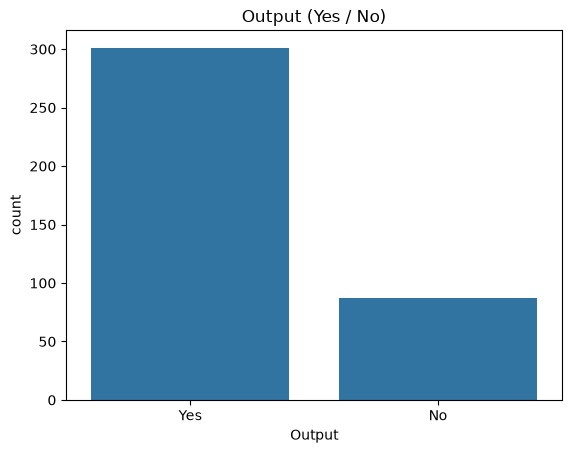

In [37]:
# How many customers said yes and no to ordering?

print(df['Output'].value_counts())
sns.countplot(x='Output', data=df)
plt.title('Output (Yes / No)')
plt.savefig('Customers Output.png')
plt.show()

### What the chart shows: Output (Yes / No)

The chart counts how many customers answered **Yes** and how many answered **No** in the Output column.

Yes:- 217 customers (about 76%)
No:- 68 customers (about 24%)

About 3 out of every 4 customers said Yes, so the data is **unbalanced**: Yes is much more common than No.

### Why are the numbers like this?
- **Most customers are existing users.** Almost all of them are Regular or Frequent customers (about 94%), and only a few are New. People who already use food delivery apps are more likely to say Yes.
- **Most customers are happy with the service.** About 81% gave positive feedback, and the Feedback chart shows that customers with positive feedback mostly said Yes.
- **The sample is mostly young students.** Earlier charts showed that students and single people say Yes more often, and they make up a big part of the data.

The business need to come up with incentives to maintain the existing customer base mainly the students. This would enable the customer gain more customers as regulars and frequents are likely to come back and with even friends. 

In [20]:
# Who says yes more often? 

# Turn Yes/No into 1/0 so we can take the average (average = share of Yes)
df['Output_num'] = df['Output'].map({'Yes': 1, 'No': 0})

# share of Yes for each marital status
df.groupby('Marital Status')['Output_num'].mean()

Marital Status
Married              0.609195
Prefer not to say    0.444444
Single               0.846561
Name: Output_num, dtype: float64

The single customers are more likely to say yes at 84.7%. 

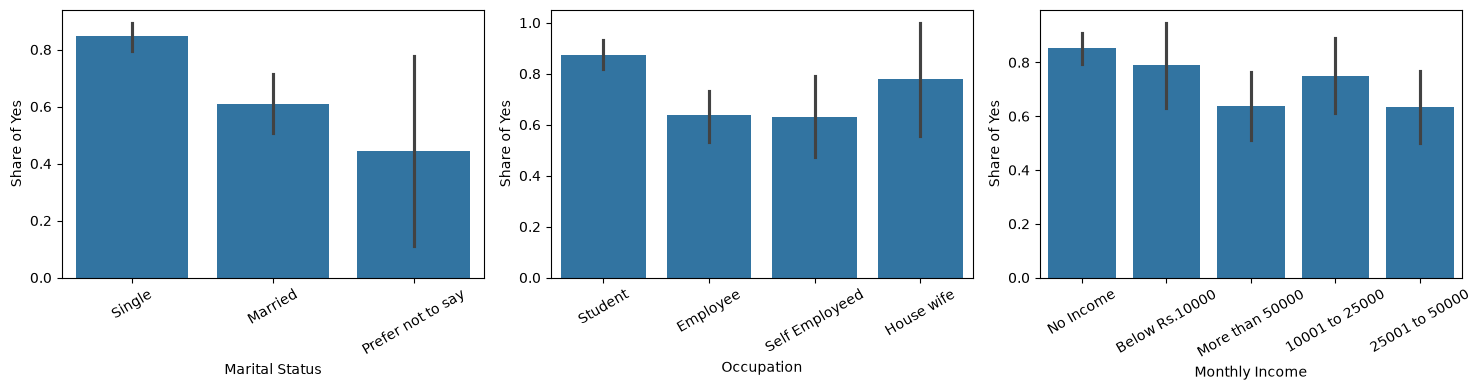

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Marital Status', 'Occupation', 'Monthly Income']):
    sns.barplot(x=col, y='Output_num', data=df, ax=ax)
    ax.set_ylabel('Share of Yes')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('Likely to say Yes.png')
plt.show()

Single people and students say Yes more often than married people and employees.

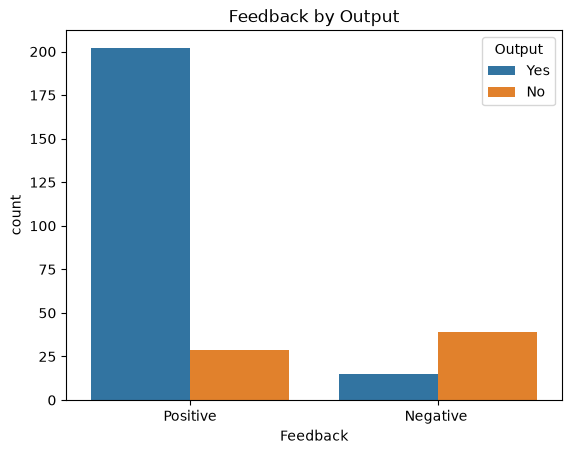

In [22]:
# Feedback

sns.countplot(x='Feedback', hue='Output', data=df)
plt.title('Feedback by Output')
plt.savefig('Customer Feedback.png')
plt.show()

Customers with feedback mostly say yes. 

## Feature Engineering

In [23]:
# 1. Age group
df['Age Group'] = pd.cut(df['Age'], bins=[17, 21, 24, 27, 40], labels=['18-21', '22-24', '25-27', '28+'])


In [24]:
# 2. Income as a number (0 = no income ... 4 = more than 50000)
income_levels = {'No Income': 0, 'Below Rs.10000': 1, '10001 to 25000': 2, '25001 to 50000': 3, 'More than 50000': 4}
df['Income Level'] = df['Monthly Income'].map(income_levels)

In [25]:
# 3. Education as a number
education_levels = {'Uneducated': 0, 'School': 1, 'Graduate': 2, 'Post Graduate': 3, 'Ph.D': 4}
df['Education Level'] = df['Educational Qualifications'].map(education_levels)

In [26]:
# 4. Family type (small or large)
df['Family Type'] = np.where(df['Family size'] <= 3, 'Small', 'Large')

In [27]:
# 5. Is the customer a student? (1 = yes, 0 = no)
df['Is Student'] = np.where(df['Occupation'] == 'Student', 1, 0)

In [28]:
# 6. Is the customer married? (1 = yes, 0 = no)
df['Is Married'] = np.where(df['Marital Status'] == 'Married', 1, 0)



In [29]:
# 7. Positive feedback (1 = positive, 0 = negative)
df['Positive Feedback'] = np.where(df['Feedback'] == 'Positive', 1, 0)


In [30]:
df[['Age', 'Age Group', 'Income Level', 'Education Level', 
    'Family Type', 'Is Student', 'Is Married', 
    'Positive Feedback']].head()

,Age,Age Group,Income Level,Education Level,Family Type,Is Student,Is Married,Positive Feedback
0,20,18-21,0,3,Large,1,0,1
1,24,22-24,1,2,Small,1,0,1
2,22,22-24,1,3,Small,1,0,0
3,22,22-24,0,2,Large,1,0,1
4,22,22-24,1,3,Large,1,0,1


In [31]:
df.head()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,...,Output,Feedback,Output_num,Age Group,Income Level,Education Level,Family Type,Is Student,Is Married,Positive Feedback
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,...,Yes,Positive,1,18-21,0,3,Large,1,0,1
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,...,Yes,Positive,1,22-24,1,2,Small,1,0,1
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,...,Yes,Negative,1,22-24,1,3,Small,1,0,0
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,...,Yes,Positive,1,22-24,0,2,Large,1,0,1
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,...,Yes,Positive,1,22-24,1,3,Large,1,0,1


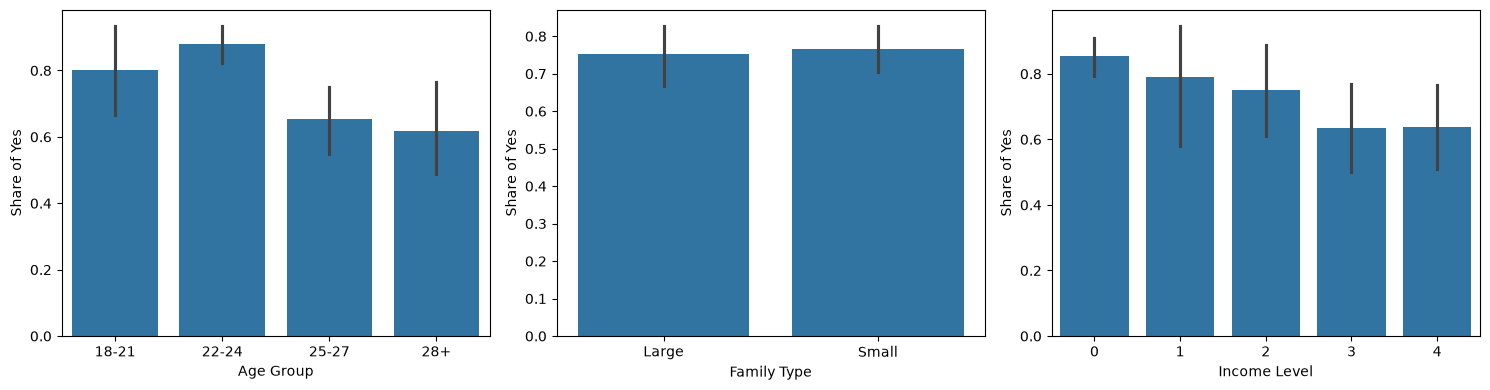

In [32]:
# Pattern Shown

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Age Group', 'Family Type', 'Income Level']):
    sns.barplot(x=col, y='Output_num', data=df, ax=ax)
    ax.set_ylabel('Share of Yes')

plt.tight_layout()
plt.savefig('Pattern per new Group.png')
plt.show()

The charts show the **share of customers who said Yes** for each new column. The overall Yes-rate is about 76%, so a group above that says Yes more often than average, and a group below it says Yes less often.

**Age Group**
- 18-21: 80% Yes
- 22-24: 88% Yes
- 25-27: 65% Yes
- 28+: 62% Yes

Younger customers (under 25) say Yes more often than older customers. The Yes-rate drops after age 24.

**Income Level**
- No income: 85% Yes
- Below Rs.10,000: 79% Yes
- Rs.10,001 to 25,000: 75% Yes
- Rs.25,001 to 50,000: 63% Yes
- More than Rs.50,000: 64% Yes

As income goes up, the Yes-rate goes down. Customers with no income say Yes the most.

**Family Type**
- Small family (1-3 people): 77% Yes
- Large family (4 or more): 75% Yes

There is almost no difference, so family size does not seem to matter much in this data.

**Other new columns**
- Students: 88% Yes, compared with 65% for non-students
- Married customers: 61% Yes, compared with 83% for non-married customers
- Positive feedback: 87% Yes, compared with 28% for negative feedback

Age, income, being a student and being married are closely linked in this data. Students are young and have no income, while older customers are more likely to be employed, earn more and be married. So the different columns are partly describing the same group of people. Students and young people are the most likely to say Yes, and older, married customers with higher incomes are less likely.

Main finding: The strongest pattern is with feedback: customers who gave positive feedback almost always said Yes. After feedback, the clearest groups are students, young customers (under 25) and customers with no income.

A pattern is not proof of a cause. Having a lower income does not necessarily make someone less likely to order. It may simply be that students make up most of the low-income group.
Some groups are small (for example, only 30 customers are aged 18-21), so their percentages can change a lot with a few customers.
Family type shows no real pattern. 

## Conclusion

- Most customers are young, single students with no income.
- Single people and students say Yes more often than married people and employees.
- Gender and customer type make little difference.
- Customers who give positive feedback mostly say Yes.

# Reccomendation

Work on maintaining the already existing customer base by giving them better service. Better service means positive feedback hence able to come back more that once. 

The management need to bring in more incentives that favour the students and single customer base more.

The management should ensure the services and food is pocket friendly so that the customer base of young and single students with no or less income come back again and again.